# Research question

This notebook trains a query-conditioned hybrid Set Transformer from scratch on the bundle exported by notebook 06. It uses the same approved cases, source records, output adapter and frozen evaluator as XGBoost.

The final 230 cases were inspected during earlier Gemma development. They remain a fixed comparison rather than an untouched test. This notebook reads no final reference answers and downloads no language-model weights.


# 1. Prepare the runtime

Install dependencies, import the libraries, then mount Drive and choose a reproducible precision mode.


## 1.1 Install dependencies

Install the supported package versions before importing the training libraries. Packages already satisfying these constraints are retained.


In [1]:
requirements = {
    "torch": ("torch>=2.4,<3", (2, 4)),
    "numpy": ("numpy>=1.26,<3", (1, 26)),
    "pandas": ("pandas>=2.2,<4", (2, 2)),
    "matplotlib": ("matplotlib>=3.8,<4", (3, 8)),
    "scikit-learn": ("scikit-learn>=1.5,<2", (1, 5)),
    "jsonschema": ("jsonschema>=4.20,<5", (4, 20))
}
get_ipython().run_line_magic(
    "pip", "install -q " + " ".join('"' + spec + '"' for spec, _ in requirements.values())
)


## 1.2 Import the libraries

Keep ordinary imports together here. The exported shared adapter and frozen scorer are imported only after checksum verification in Section 2.


In [ ]:
import copy
import csv
import hashlib
import importlib.metadata as metadata
import importlib.util
import json
import os
import random
import shutil
import sys
import tempfile
import time
import uuid
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import jsonschema
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from google.colab import drive
from torch.nn import functional as F


## 1.3 Mount Drive and configure the run

Set `RESUME_RUN` to an existing run directory under `OUTPUT_ROOT` only if it contains `last.pt` or `best.pt`. Recovery repeats any unfinished epoch using the original settings and precision mode.

DRIVE_ROOT is the project anchor. Smoke mode is enabled, and full training and final inference remain disabled. Set `TRAIN_PRECISION = "fp32"` before Run All for a fresh FP32 run on the T4. FP32 uses more memory, so start in smoke mode with the existing size-aware batching and activation checkpointing.

Upload the repository file `notebooks/model_source.py` to `DRIVE_ROOT / "model_source.py"`, next to `prepared_data`. Keep the prepared bundle and its manifest unchanged. Section 3 imports a checked runtime copy of this implementation.


In [3]:
drive.mount("/content/drive")


Mounted at /content/drive


In [4]:
DRIVE_ROOT = Path("/content/drive/MyDrive/1_MSAI/8_AIH/HRP/data")
DATA_ROOT = DRIVE_ROOT / "prepared_data"
OUTPUT_ROOT = DRIVE_ROOT / "hybrid_set_transformer_outputs"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

SEED = 42
TRAIN_PRECISION = "fp16"  # Choose "fp32" for an explicit CUDA FP32 run
SMOKE_TEST = True
RUN_FULL_TRAINING = False
RUN_FINAL_CHALLENGE_INFERENCE = False
MODEL_SETTINGS_FROZEN = False
# Use the full path of a previous run only when continuing its training
RESUME_RUN = None
OVERFIT_STEPS = 200


## 1.4 Set seeds and inspect hardware

Record the device, CUDA version and memory. Deterministic settings reduce variation, though hardware and GPU kernels can still affect numerical results.


In [5]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if TRAIN_PRECISION not in ("fp16", "fp32"):
    raise ValueError('TRAIN_PRECISION must be "fp16" or "fp32"')
USE_AMP = DEVICE.type == "cuda" and TRAIN_PRECISION == "fp16"
hardware_info = {
    "device": str(DEVICE), "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda, "training_precision": "fp16" if USE_AMP else "fp32"
}
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    hardware_info.update(gpu=props.name, total_memory_gb=round(props.total_memory / 2**30, 2),
                         free_memory_gb=round(free_bytes / 2**30, 2))
else:
    print("CPU fallback is intended for smoke tests")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

hardware_info


{'device': 'cuda',
 'cuda_available': True,
 'cuda_version': '13.0',
 'training_precision': 'fp16',
 'gpu': 'Tesla T4',
 'total_memory_gb': 14.56,
 'free_memory_gb': 14.46}

## 1.5 Record package versions

Keep runtime versions with the experiment so another Colab session can reproduce its environment.


In [6]:
runtime_versions_df = pd.DataFrame([{"package": "Python", "version": sys.version}] +
    [{"package": name, "version": metadata.version(name)} for name in requirements])
runtime_versions_df


,package,version
0,Python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
1,torch,2.14.1+cu130
2,numpy,2.4.6
3,pandas,2.2.3
4,matplotlib,3.10.0
5,scikit-learn,1.6.1
6,jsonschema,4.26.0


# 2. Verify the prepared dataset

Check the exported code and data against the checksum manifest before importing the shared contract or reading the labelled splits.


## 2.1 Check files and checksums

An incomplete or changed bundle stops the run. Every required code and data file must be covered by the manifest.


In [7]:
required_names = [
    "manifest.json", "bundle_config.json", "train.jsonl.gz", "stop.jsonl.gz", "calibration.jsonl.gz",
    "challenge_inputs.jsonl.gz", "ingredient_identities.jsonl.gz",
    "split_manifest.json", "dataset_schema.json", "encoding.json",
    "output_schema.json", "preparation_report.json", "otc_shared.py",
    "frozen/hrp/__init__.py", "frozen/hrp/data_cleaning.py",
    "frozen/hrp/challenge_evaluation.py", "frozen/hrp/challenge_scoring_v3.py"
]
missing = [name for name in required_names if not (DATA_ROOT / name).is_file()]
if missing:
    print("Upload these paths under", DATA_ROOT)
    print("\n".join(missing))
    raise FileNotFoundError("The prepared data folder is incomplete")

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

manifest = json.loads((DATA_ROOT / "manifest.json").read_text(encoding="utf-8"))
if set(required_names) - {"manifest.json"} - set(manifest["files"]):
    raise ValueError("Required bundle files are missing from the checksum manifest")
for name, expected in manifest["files"].items():
    path = (DATA_ROOT / name).resolve()
    if not path.is_relative_to(DATA_ROOT.resolve()):
        raise ValueError("Manifest path leaves the data folder")
    if not path.is_file() or file_hash(path) != expected:
        raise ValueError("Bundle checksum mismatch " + name)
if manifest["challenge_references_included"] or manifest["saved_model_responses_included"]:
    raise ValueError("The training bundle contains prohibited material")
bundle_hash = file_hash(DATA_ROOT / "manifest.json")


## 2.2 Import the verified contract

Use cached copies of the exported adapter and frozen scorer. Restart a runtime holding a different copy so both models use the same output policy.


In [8]:
# Cache code on the runtime disk while preserving its verified bytes
CACHE_ROOT = Path("/content/hrp_cache") / bundle_hash[:16]
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
shutil.copytree(DATA_ROOT / "frozen", CACHE_ROOT / "frozen", dirs_exist_ok=True)
shutil.copyfile(DATA_ROOT / "otc_shared.py", CACHE_ROOT / "otc_shared.py")
sys.path[:0] = [str(CACHE_ROOT / "frozen"), str(CACHE_ROOT)]
from otc_shared import (
    STATUS, SUPPORTED, check_payload, flatten, read_jsonl, write_jsonl, dump_json,
    sha_file, sha_value, calibrate, evaluate, adapt_case, raw_metrics, plot_confusion, metric
)
import otc_shared as shared_module
from hrp import challenge_evaluation as contract
if Path(shared_module.__file__).resolve() != (CACHE_ROOT / "otc_shared.py").resolve():
    raise RuntimeError("Restart the runtime to load the verified shared code")
if Path(contract.__file__).resolve() != (CACHE_ROOT / "frozen/hrp/challenge_evaluation.py").resolve():
    raise RuntimeError("Restart the runtime to load the verified frozen scorer")
from hrp.challenge_scoring_v3 import SCORING_CONTRACT_VERSION
from hrp.data_cleaning import normalize_name
schema_info = json.loads((DATA_ROOT / "dataset_schema.json").read_text(encoding="utf-8"))
encoding = json.loads((DATA_ROOT / "encoding.json").read_text(encoding="utf-8"))
split_info = json.loads((DATA_ROOT / "split_manifest.json").read_text(encoding="utf-8"))
output_schema = json.loads((DATA_ROOT / "output_schema.json").read_text(encoding="utf-8"))
if schema_info["statuses"] != STATUS or schema_info["scoring_contract"] != SCORING_CONTRACT_VERSION:
    raise ValueError("Dataset and scoring versions differ")
if schema_info.get("candidate_labels_semantics") != "Source support rather than query intent":
    raise ValueError("Re-export the bundle with the reviewed source-support label definition")
if encoding["vocabulary_size"] != 257 or encoding["candidate_truncation"]:
    raise ValueError("Unexpected input encoding")
resolver = contract.IdentityResolver(list(read_jsonl(DATA_ROOT / "ingredient_identities.jsonl.gz")))


## 2.3 Check isolation and supervision

Verify case IDs, family groups and normalized inputs again after transfer to Drive. Labels and family metadata remain outside predictor payloads.


In [9]:
data = {part: list(read_jsonl(DATA_ROOT / (part + ".jsonl.gz")))
        for part in ("train", "stop", "calibration")}
seen_ids, seen_groups, seen_keys = {}, {}, {}
for part, rows in data.items():
    if len(rows) != schema_info["case_counts"][part]:
        raise ValueError("Unexpected split count " + part)
    if {r["case_id"] for r in rows} != set(split_info["case_ids"][part]):
        raise ValueError("Split IDs differ from the manifest")
    seen_ids[part], seen_groups[part], seen_keys[part] = set(), set(), set()
    for row in rows:
        if set(row) != {"case_id", "payload", "target", "candidate_labels", "meta"}:
            raise ValueError("Unexpected training row fields")
        check_payload(row["payload"])
        contract.parse_output(row["target"], row["payload"])
        if len(row["candidate_labels"]) != len(row["payload"]["products"]):
            raise ValueError("Candidate target count mismatch")
        for item, ys in zip(row["payload"]["products"], row["candidate_labels"]):
            if len(ys) != len(item["candidates"]) or any(y not in (0, 1) for y in ys):
                raise ValueError("Invalid candidate targets")
        seen_ids[part].add(row["case_id"])
        seen_groups[part].update(row["meta"]["families"])
        requests = [i["request"] for i in row["payload"]["products"]]
        query = requests[0] if len(requests) == 1 else dict(zip(("product_a", "product_b"), requests))
        seen_keys[part].add(contract.semantic_input_key(query))
    if len(seen_ids[part]) != len(rows):
        raise ValueError("Duplicate case IDs")
    if seen_ids[part] & set(split_info["challenge_case_ids"]):
        raise ValueError("Final case reached a labelled split")
    if seen_groups[part] & set(split_info["challenge_family_ids"]):
        raise ValueError("Final family reached a labelled split")
    if part == "train" and seen_groups[part] & set(split_info["quarantined_training_family_ids"]):
        raise ValueError("Quarantined family reached training")
for a, b in (("train", "stop"), ("train", "calibration"), ("stop", "calibration")):
    if seen_ids[a] & seen_ids[b] or seen_groups[a] & seen_groups[b] or seen_keys[a] & seen_keys[b]:
        raise ValueError("Data splits overlap")
print("Verified dataset", {"bundle_sha256": bundle_hash, "cases": {part: len(rows) for part, rows in data.items()}})


Verified dataset {'bundle_sha256': 'a058335aa97fe42907c66b6ce7072ee80cf6e2892d6e5a096509f97dffe28095', 'cases': {'train': 75372, 'stop': 9002, 'calibration': 3352}}


## 2.4 Inspect split supervision

Review the verified split counts and identify statuses without training supervision.


In [10]:
audit = json.loads((DATA_ROOT / "preparation_report.json").read_text(encoding="utf-8"))
print("Statuses without training supervision", schema_info["unsupported_training_statuses"])
split_counts_df = pd.DataFrame({part: audit[part]["counts"] for part in data}).fillna(0).astype(int)
split_counts_df


Statuses without training supervision ['NO_MATCH']


,train,stop,calibration
cases,75372,9002,3352
two product cases,19491,1905,590
EXACT_NDC_IDENTIFIED,43089,3584,1252
complete formulation,7883,690,226
source support positive,49920,3906,1306
source support negative,54526,7825,2843
mixed source support requests,280,28,10
known ingredient ambiguity,102,0,0
unresolved source abstention,48694,7054,2662
INSUFFICIENT_INFORMATION,48796,7054,2662


# 3. Encode queries and variable candidate sets

The query tower reads the supplied medicine fields. The source tower reads names, ingredients, strengths, form, route, identifiers and provenance. Source assessments are labels and are not encoded.


## 3.1 Load the shared model implementation

Upload `notebooks/model_source.py` to `/content/drive/MyDrive/1_MSAI/8_AIH/HRP/data/model_source.py`. The notebook imports a byte-identical runtime copy after Section 2 has verified the shared adapter and frozen scorer. The same source file is copied into the inference package.

Query and candidate field encoders remain in that module so training and export use one implementation.


In [ ]:
MODEL_SOURCE_PATH = DRIVE_ROOT / "model_source.py"
MODEL_RUNTIME_PATH = CACHE_ROOT / "model_source.py"
if not MODEL_SOURCE_PATH.is_file():
    raise FileNotFoundError("Upload notebooks/model_source.py to " + str(MODEL_SOURCE_PATH))
shutil.copyfile(MODEL_SOURCE_PATH, MODEL_RUNTIME_PATH)
import model_source as model_lib
if (Path(model_lib.__file__).resolve() != MODEL_RUNTIME_PATH.resolve()
        or model_lib.SOURCE_SHA256 != file_hash(MODEL_SOURCE_PATH)):
    raise RuntimeError("Restart the runtime to load the current model_source.py; checkpoints remain usable")

QUERY_NAMES = model_lib.QUERY_NAMES
CHUNK_SIZE = int(encoding["text_chunk_bytes"])
SET_SLOT_BUDGET = 512
model_lib.configure_runtime(encoding, DEVICE, use_amp=USE_AMP, seed=SEED, set_slot_budget=SET_SLOT_BUDGET)
query_texts = model_lib.query_texts
candidate_texts = model_lib.candidate_texts


## 3.2 Encode complete text in chunks

A fixed byte vocabulary needs no fitted tokenizer. Overlapping chunks retain every source byte. Cache compact integer arrays on the CPU and convert only the active batch to tensor indices.


In [ ]:
text_chunks = model_lib.text_chunks
encode_fields = model_lib.encode_fields


## 3.3 Build request datasets

Cases with one or two medicines become one or two request sets. Case grouping is restored before the output adapter runs.


In [ ]:
MedicineSets = model_lib.MedicineSets


## 3.4 Pad and mask each batch

Masks distinguish source records, padding and the sentinel for an empty set. Only real source records contribute to source-support loss.


In [ ]:
collate = model_lib.collate


## 3.5 Pack batches by set size

Reduce batch size when large sets would cause excessive padding. Every candidate is retained, including single sets above the padding budget. Predictions are restored to their original order.


In [ ]:
move = model_lib.move
pack_batches = model_lib.pack_batches
train_batches = model_lib.train_batches
loader = model_lib.loader


# 4. Build the hybrid Set Transformer

Separate character CNNs encode queries and source fields. Query cross attention conditions the candidates, two set-attention layers capture relationships, and attention pooling forms a permutation-invariant request representation.


## 4.1 Encode character chunks

Convolution and pooling encode each field. Large training batches use activation checkpointing to reduce memory while preserving the forward computation.


In [ ]:
CharacterCNN = model_lib.CharacterCNN


## 4.2 Define attention blocks

Residual connections, normalization and a feed-forward layer follow attention. Masks keep padding out of the source set.


In [ ]:
AttentionBlock = model_lib.AttentionBlock


## 4.3 Fuse the query and source set

Candidates have no position encoding. Set size helps distinguish one record from several. The candidate output key means source support rather than query-specific correctness.


In [ ]:
HybridSetTransformer = model_lib.HybridSetTransformer


## 4.4 Choose the run configuration

Full training starts with hidden size 128, four heads, two set layers, dropout 0.1, batch size 32 and at most 20 epochs. Smoke mode uses fewer approved cases.


In [19]:
MODEL_CONFIG = {"hidden": 128, "heads": 4, "layers": 2, "dropout": 0.1}
TRAIN_CONFIG = {
    "seed": SEED, "batch_size": 32, "max_epochs": 20, "learning_rate": 3e-4,
    "weight_decay": 1e-3, "patience": 4, "gradient_clip": 1.0,
    "loss_weights": {"candidate": 1.0, "sufficiency": 1.0, "status": 1.0, "form": 0.5},
    "set_slot_budget": SET_SLOT_BUDGET
}
if SMOKE_TEST and RUN_FULL_TRAINING:
    raise ValueError("Choose either smoke testing or full training")
if not SMOKE_TEST and not RUN_FULL_TRAINING:
    raise RuntimeError("Enable RUN_FULL_TRAINING deliberately for a complete experiment")

def sample_rows(rows, size):
    indices = np.random.default_rng(SEED).permutation(len(rows))[:size]
    return [rows[int(i)] for i in sorted(indices)]

used = {
    "train": sample_rows(data["train"], 128) if SMOKE_TEST else data["train"],
    "stop": sample_rows(data["stop"], 64) if SMOKE_TEST else data["stop"],
    "calibration": sample_rows(data["calibration"], 64) if SMOKE_TEST else data["calibration"]
}
datasets = {part: MedicineSets(rows) for part, rows in used.items()}
if SMOKE_TEST:
    TRAIN_CONFIG.update(max_epochs=3, batch_size=8, patience=2)


## 4.5 Inspect class balance

Compute weights from the actual training subset. Mask unobserved status logits and record their names so missing supervision is not presented as learned behavior.


In [20]:
status_counts = np.bincount([y["status"] for y in datasets["train"].labels], minlength=6)
MODEL_CONFIG["active_status"] = (status_counts > 0).tolist()
status_weights = np.zeros(6, dtype=np.float32)
status_weights[status_counts > 0] = np.minimum(
    10.0, np.sqrt(status_counts.sum() / (max(1, (status_counts > 0).sum()) * status_counts[status_counts > 0]))
)
positive_weights, binary_counts = {}, {}
for key in ("candidate", "sufficiency", "form"):
    ys = [v for y in datasets["train"].labels for v in y["candidate"]] if key == "candidate" else [
        y[key] for y in datasets["train"].labels
    ]
    positives, negatives = sum(ys), len(ys) - sum(ys)
    positive_weights[key] = min(10.0, max(0.1, negatives / max(1, positives)))
    binary_counts[key] = {"positive": int(positives), "negative": int(negatives)}
status_balance_df = pd.DataFrame({
    "status": STATUS, "training_count": status_counts, "loss_weight": status_weights,
    "supervised": status_counts > 0
})
status_balance_df


,status,training_count,loss_weight,supervised
0,EXACT_NDC_IDENTIFIED,79,0.716002,True
1,FORMULATION_IDENTIFIED,2,4.500000,True
2,INGREDIENT_SET_IDENTIFIED,0,0.000000,False
3,INSUFFICIENT_INFORMATION,80,0.711512,True
4,NO_MATCH,0,0.000000,False
5,SOURCE_CONFLICT,1,6.363961,True


## 4.6 Inspect binary target balance

Record the binary label counts and their existing positive loss weights.


In [21]:
binary_balance_df = pd.DataFrame([{"head": key, **counts, "positive_weight": positive_weights[key]}
                                  for key, counts in binary_counts.items()])
binary_balance_df


,head,positive,negative,positive_weight
0,candidate,103,86,0.834951
1,sufficiency,81,81,1.000000
2,form,14,148,10.000000


# 5. Losses and bounded smoke checks

The objective combines source support, evidence sufficiency, status and formulation availability. Several records can have positive source-support labels without establishing a unique intended product.


## 5.1 Define the multitask loss

Average source-support loss within each request. Unseen validation classes retain the existing finite error penalty. Logits and loss reductions use FP32 explicitly; target labels, weights and objectives are unchanged.


In [22]:
status_weight_tensor = torch.tensor(status_weights, device=DEVICE)
positive_tensors = {key: torch.tensor(value, device=DEVICE) for key, value in positive_weights.items()}

def status_loss(logits, targets, balanced=True):
    # Unseen classes retain a fixed validation penalty rather than disappearing from the loss
    log_probabilities = F.log_softmax(logits.float(), dim=-1).clamp_min(float(np.log(1e-7)))
    weights = torch.where(status_weight_tensor > 0, status_weight_tensor,
                          torch.ones_like(status_weight_tensor)) if balanced else None
    return F.nll_loss(log_probabilities, targets, weight=weights)

def losses(output, target, features, balanced=True):
    mask = features["real"]
    candidate = F.binary_cross_entropy_with_logits(
        output["candidate"].float(), target["candidate"], reduction="none",
        pos_weight=positive_tensors["candidate"] if balanced else None
    )
    per_request = (candidate * mask).sum(1) / mask.sum(1).clamp_min(1)
    eligible = mask.any(1)
    candidate_loss = per_request[eligible].mean() if eligible.any() else output["candidate"].float().sum() * 0
    result = {
        "candidate": candidate_loss,
        "status": status_loss(output["status"], target["status"], balanced),
        "sufficiency": F.binary_cross_entropy_with_logits(
            output["sufficiency"].float(), target["sufficiency"],
            pos_weight=positive_tensors["sufficiency"] if balanced else None),
        "form": F.binary_cross_entropy_with_logits(
            output["form"].float(), target["form"],
            pos_weight=positive_tensors["form"] if balanced else None)
    }
    result["total"] = sum(TRAIN_CONFIG["loss_weights"][name] * loss for name, loss in result.items())
    return result


def nonfinite_names(named_tensors):
    named_tensors = [(name, value) for name, value in named_tensors if value is not None]
    if not named_tensors:
        return []
    finite = torch.stack([torch.isfinite(value).all() for _, value in named_tensors]).cpu().tolist()
    return [name for (name, _), ok in zip(named_tensors, finite) if not ok]


def clip_finite_gradients(test_model, max_norm):
    bad = nonfinite_names((name, p.grad) for name, p in test_model.named_parameters())
    if bad:
        raise RuntimeError("Nonfinite gradients before clipping: " + str(bad[:12]))
    # PyTorch checks the total norm before modifying any finite gradients.
    return torch.nn.utils.clip_grad_norm_(test_model.parameters(), max_norm, error_if_nonfinite=True)


## 5.2 Overfit a tiny training sample

A temporary model checks forward and backward passes using only approved training requests. Its weights are discarded after loss reduction and status accuracy are checked.


In [23]:
def tiny_overfit():
    # These requests are all drawn from approved training data
    tiny = [datasets["train"][i] for i in range(min(8, len(datasets["train"])))]
    features, target, _, _ = collate(tiny)
    features, target = move(features), move(target)
    cfg = dict(MODEL_CONFIG, dropout=0.0)
    temporary = HybridSetTransformer(**cfg).to(DEVICE)
    optimizer = torch.optim.AdamW(temporary.parameters(), lr=0.003, weight_decay=0.0)
    temporary.train()
    initial = None
    final = None
    for step in range(OVERFIT_STEPS):
        optimizer.zero_grad(set_to_none=True)
        output = temporary(features)
        loss = losses(output, target, features, balanced=False)["total"]
        if not torch.isfinite(loss):
            raise RuntimeError("Nonfinite smoke loss")
        loss.backward()
        clip_finite_gradients(temporary, 1.0)
        optimizer.step()
        if initial is None:
            initial = float(loss.detach())
        final = float(loss.detach())
        accuracy = float((output["status"].argmax(-1) == target["status"]).float().mean())
        if step >= 30 and final < initial * 0.25 and accuracy >= 0.95:
            break
    print("Tiny overfit", {"steps": step + 1, "first_loss": initial,
                          "last_loss": final, "status_accuracy": accuracy})
    if not (final < initial * 0.4 and accuracy >= 0.95):
        raise RuntimeError("Tiny training overfit check failed and needs investigation")

    check_set_shapes(temporary)
    del temporary, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


## 5.3 Check invariance and empty sets

Reversing the candidate order must preserve request decisions and reverse the corresponding per-record scores. Empty sets must produce finite outputs.


In [24]:
def check_set_shapes(test_model):
    test_model.eval()
    # Test set invariance with at least two real candidates from training
    index = next((i for i, item in enumerate(datasets["train"].items) if len(item["candidates"]) > 1), None)
    if index is None:
        pool = MedicineSets(data["train"])
        index = next((i for i, item in enumerate(pool.items) if len(item["candidates"]) > 1), None)
    else:
        pool = datasets["train"]
    if index is None:
        raise RuntimeError("No training candidate set can test permutation invariance")
    item, label, _ = pool[index]
    reverse = copy.deepcopy(item)
    reverse["candidates"].reverse()
    label_reverse = dict(label, candidate=list(reversed(label["candidate"])))
    left = move(collate([(item, label, 0)])[0])
    right = move(collate([(reverse, label_reverse, 0)])[0])
    with torch.no_grad():
        a, b = test_model(left), test_model(right)
    if not torch.allclose(a["status"], b["status"], atol=2e-4, rtol=2e-4):
        raise RuntimeError("Set pooling is not permutation invariant")
    n = len(item["candidates"])
    if not torch.allclose(a["candidate"][0, :n], b["candidate"][0, :n].flip(0), atol=2e-4, rtol=2e-4):
        raise RuntimeError("Candidate scores do not follow candidate order")
    empty = {"request": item["request"], "candidate_count": 0, "candidates": []}
    with torch.no_grad():
        output = test_model(move(collate([(empty, None, 0)])[0]))
    if not all(torch.isfinite(value).all() for value in output.values()):
        raise RuntimeError("Empty candidate set has nonfinite outputs")


## 5.4 Run the checks and reset weights

Fresh training starts from the fixed seed after discarding the temporary weights. Resumption restores its original saved state later.


In [25]:
if RESUME_RUN is None:
    tiny_overfit()
else:
    print("Resuming the saved experiment after its original smoke checks")
# Reset the seed after discarding smoke weights
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
model = HybridSetTransformer(**MODEL_CONFIG).to(DEVICE)
print("Trainable parameters", sum(p.numel() for p in model.parameters() if p.requires_grad))


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:910.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Tiny overfit {'steps': 31, 'first_loss': 3.150477886199951, 'last_loss': 2.151635999325663e-05, 'status_accuracy': 1.0}
Trainable parameters 881513


# 6. Train and resume checkpoints

Use the existing AdamW optimizer, clipping threshold, cosine schedule and early stopping. CUDA FP16 uses GradScaler; the explicit FP32 option disables autocast and scaling.

The previous loop clipped gradients and raised before GradScaler could skip an overflowing step and lower its scale. That explains why an expected scale overflow could stop the run, but the traceback alone cannot prove the gradients were recoverable. Section 6.4 diagnoses the same batch without loss scaling before deciding whether training can continue.


## 6.1 Create or verify a run folder

Fresh runs get new folders. Resumption requires matching data, architecture, training settings and package versions.


In [26]:
NUMERICAL_POLICY = {"max_consecutive_overflows": 3, "max_overflows_per_epoch": 8}

if RESUME_RUN is None:
    run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
    RUN_ROOT = OUTPUT_ROOT / ("set_transformer_" + run_name)
    RUN_ROOT.mkdir(exist_ok=False)
else:
    RUN_ROOT = Path(RESUME_RUN).resolve()
    if not RUN_ROOT.is_relative_to(OUTPUT_ROOT.resolve()) or not any((RUN_ROOT / name).is_file() for name in ("last.pt", "best.pt")):
        raise ValueError("Resume folder must contain a checkpoint under OUTPUT_ROOT")

run_config = {
    "model": MODEL_CONFIG, "training": TRAIN_CONFIG,
    "smoke_test": SMOKE_TEST, "full_training": RUN_FULL_TRAINING,
    "bundle_manifest_sha256": bundle_hash,
    "shared_code_sha256": file_hash(DATA_ROOT / "otc_shared.py"),
    "encoding": encoding, "status_counts": status_counts.tolist(),
    "positive_weights": positive_weights,
    "packages": {name: metadata.version(name) for name in requirements},
    "python": sys.version, "device": str(DEVICE),
    "precision": "fp16" if USE_AMP else "fp32",
    "numerical_policy": NUMERICAL_POLICY,
    "gpu_name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None
}
if RESUME_RUN is None:
    dump_json(RUN_ROOT / "configuration.json", run_config)
else:
    saved_config = json.loads((RUN_ROOT / "configuration.json").read_text(encoding="utf-8"))
    for key in ("model", "training", "smoke_test", "full_training", "bundle_manifest_sha256",
                "shared_code_sha256", "encoding", "status_counts", "positive_weights", "packages"):
        if saved_config[key] != run_config[key]:
            raise ValueError("Resume configuration changed " + key)

    if saved_config["device"].split(":")[0] != DEVICE.type:
        raise ValueError("Resume device type/AMP mode changed; use the original CPU or CUDA runtime")
    saved_precision = saved_config.get("precision", "fp16" if DEVICE.type == "cuda" else "fp32")
    if saved_precision != run_config["precision"]:
        raise ValueError("Resume precision changed; use the saved mode or start a fresh run")
    if saved_config.get("numerical_policy", NUMERICAL_POLICY) != NUMERICAL_POLICY:
        raise ValueError("Resume numerical policy changed")
    # Keep the original identity even when a restarted runtime reports a different GPU name.
    run_config = saved_config


## 6.2 Configure optimization and checkpoint state

Save optimizer, scheduler, scaler, history and random states as well as weights. Atomic replacement avoids partial checkpoint files.


In [27]:
optimizer = torch.optim.AdamW(model.parameters(), lr=TRAIN_CONFIG["learning_rate"],
                              weight_decay=TRAIN_CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TRAIN_CONFIG["max_epochs"])
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
numerical_state = dict.fromkeys(
    ("overflow_steps", "skipped_steps", "optimizer_steps", "scale_decreases", "scale_increases", "consecutive_overflows"), 0
)
history, best_loss, bad_epochs, first_epoch, elapsed_training = [], float("inf"), 0, 0, 0.0

def save_checkpoint(path, state):
    temp = path.with_suffix(".tmp")
    torch.save(state, temp)
    os.replace(temp, path)

def checkpoint(epoch):
    return {
        "epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
        "best_loss": best_loss, "bad_epochs": bad_epochs, "history": history,
        "elapsed_training": elapsed_training,
        "numerical_state": dict(numerical_state), "numerical_policy": dict(NUMERICAL_POLICY),
        "config_sha256": sha_value(run_config),
        "python_rng": random.getstate(), "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None
    }


In [28]:
def atomic_csv(path, frame):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    frame.to_csv(temp, index=False)
    os.replace(temp, path)

def normalize_history(rows, completed_epoch):
    rows = [dict(row) for row in rows]
    if [row["epoch"] for row in rows] != list(range(1, completed_epoch + 2)):
        raise ValueError("Checkpoint history has missing or duplicate epochs")
    best = float("inf")
    for row in rows:
        # Older checkpoints omitted LR. Reconstruct the LR used for that epoch
        # from the unchanged cosine schedule, rather than the post-step LR.
        epoch_index = row["epoch"] - 1
        expected_lr = TRAIN_CONFIG["learning_rate"] * (1 + np.cos(np.pi * epoch_index / TRAIN_CONFIG["max_epochs"])) / 2
        row.setdefault("learning_rate", float(expected_lr))
        row.setdefault("learning_rate_reconstructed", True)
        if row["stop_total_loss"] < best - 1e-4:
            best = row["stop_total_loss"]
        row["best_validation_loss"] = best
    return rows

def export_history(root, rows):
    # The checkpoint is authoritative if an interruption occurred during export.
    root = Path(root)
    dump_json(root / "history.json", rows)
    atomic_csv(root / "history.csv", pd.DataFrame(rows))

def optimizer_to_parameter_devices(optimizer):
    def relocate(value, device):
        if isinstance(value, torch.Tensor):
            return value.to(device)
        if isinstance(value, dict):
            return {key: relocate(item, device) for key, item in value.items()}
        if isinstance(value, (list, tuple)):
            return type(value)(relocate(item, device) for item in value)
        return value
    for group in optimizer.param_groups:
        for parameter in group["params"]:
            for key, value in optimizer.state[parameter].items():
                # AdamW moments follow parameters. Its scalar step stays on CPU
                # unless capturable/fused optimization requires a device step.
                device = parameter.device if key != "step" or group.get("capturable") or group.get("fused") else torch.device("cpu")
                optimizer.state[parameter][key] = relocate(value, device)

## 6.3 Restore the saved run

Restore model and optimizer state before the random generators. The optimizer loader handles its own device rules for moments and step counters.

Both checkpoint identities are checked against the saved configuration. AdamW moments move to their parameter devices; scalar step counters retain the optimizer-required device. CPU/CUDA mode changes are rejected so AMP state remains compatible.


In [29]:
if RESUME_RUN is not None:
    expected_config_hash = sha_value(run_config)
    states = {}
    for name in ("last.pt", "best.pt"):
        path = RUN_ROOT / name
        if path.is_file():
            saved = torch.load(path, map_location="cpu", weights_only=False)
            if saved["config_sha256"] != expected_config_hash:
                raise ValueError("Checkpoint configuration identity differs " + name)
            normalized = normalize_history(saved["history"], saved["epoch"])
            if not normalized or not np.isclose(normalized[-1]["best_validation_loss"], saved["best_loss"]):
                raise ValueError("Checkpoint best loss disagrees with history " + name)
            if saved["scheduler"]["last_epoch"] != saved["epoch"] + 1:
                raise ValueError("Checkpoint scheduler disagrees with completed epoch " + name)
            states[name] = saved
    # best.pt may be one completed epoch ahead if interruption preceded last.pt.
    state = max(states.values(), key=lambda saved: saved["epoch"])
    if "best.pt" not in states or (state["epoch"] > states["best.pt"]["epoch"] and state["bad_epochs"] == 0):
        if state["bad_epochs"] != 0:
            raise ValueError("Best checkpoint is missing and cannot be reconstructed from last.pt")
        save_checkpoint(RUN_ROOT / "best.pt", state)
    if "last.pt" not in states or state["epoch"] > states["last.pt"]["epoch"]:
        save_checkpoint(RUN_ROOT / "last.pt", state)
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    optimizer_to_parameter_devices(optimizer)
    scheduler.load_state_dict(state["scheduler"])
    scaler.load_state_dict(state["scaler"])
    if state.get("numerical_policy", NUMERICAL_POLICY) != NUMERICAL_POLICY:
        raise ValueError("Checkpoint numerical policy changed")
    numerical_state.update(state.get("numerical_state", {}))
    history = normalize_history(state["history"], state["epoch"])
    best_loss, bad_epochs = state["best_loss"], state["bad_epochs"]
    first_epoch, elapsed_training = state["epoch"] + 1, state["elapsed_training"]
    export_history(RUN_ROOT, history)
    random.setstate(state["python_rng"])
    np.random.set_state(state["numpy_rng"])
    torch.set_rng_state(state["torch_rng"])
    if DEVICE.type == "cuda" and state["cuda_rng"] is not None:
        if len(state["cuda_rng"]) != torch.cuda.device_count():
            raise ValueError("CUDA RNG device count differs from the saved runtime")
        torch.cuda.set_rng_state_all(state["cuda_rng"])
    print("Resuming after completed epoch", first_epoch)


## 6.4 Run one epoch

Check every output head and loss, then inspect unscaled gradients before clipping. A finite forward pass with nonfinite scaled gradients triggers a diagnostic replay of the same batch without scaling, with its original dropout RNG state. Only a finite unscaled FP16 replay is treated as recoverable scale overflow. A failing replay is checked in FP32 and stops with named gradient diagnostics.

GradScaler skips each recoverable overflowing step and updates its scale. Three consecutive overflows or eight in one epoch stop training. Every overflow and scale change is appended to `numerical_events.jsonl`; epoch counts and scale endpoints enter history, and cumulative counts enter checkpoints. Replay performs no optimizer step and restores the active RNG state.


In [30]:
def record_numerical_event(event):
    with (RUN_ROOT / "numerical_events.jsonl").open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(event, allow_nan=False) + "\n")


def diagnose_backward(features, target, rng_state, amp):
    devices = [DEVICE.index if DEVICE.index is not None else torch.cuda.current_device()] if DEVICE.type == "cuda" else []
    try:
        # Reproduce dropout without changing the next training batch's RNG state.
        with torch.random.fork_rng(devices=devices):
            torch.set_rng_state(rng_state["cpu"])
            if devices:
                torch.cuda.set_rng_state(rng_state["cuda"], devices[0])
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                output = model(features)
            parts = losses(output, target, features)
            bad_outputs = nonfinite_names(output.items())
            bad_losses = nonfinite_names(parts.items())
            bad_gradients = []
            if not bad_outputs and not bad_losses:
                named = [(name, p) for name, p in model.named_parameters() if p.requires_grad]
                gradients = torch.autograd.grad(parts["total"], [p for _, p in named], allow_unused=True)
                bad_gradients = nonfinite_names((name, g) for (name, _), g in zip(named, gradients))
            return {"finite": not (bad_outputs or bad_losses or bad_gradients),
                    "bad_outputs": bad_outputs, "bad_losses": bad_losses,
                    "bad_gradients": bad_gradients[:12]}
    except RuntimeError as exc:
        return {"finite": False, "error": str(exc), "error_type": type(exc).__name__}


def run_epoch(dataset, train=False, epoch=0):
    model.train(train)
    totals, count, correct, sufficient_correct = Counter(), 0, 0, 0
    counts = Counter()
    scale_start = scaler.get_scale()
    batch_loader = loader(dataset, TRAIN_CONFIG["batch_size"], epoch if train else None)
    for batch_index, (features, target, indices, candidate_counts) in enumerate(batch_loader):
        features, target = move(features), move(target)
        context = {"epoch": epoch + 1, "batch": batch_index + 1, "train": train,
                   "request_indices": [int(i) for i in indices], "candidate_counts": candidate_counts,
                   "query_chunks": features["query"]["tokens"].shape[0],
                   "candidate_chunks": features["candidate"]["tokens"].shape[0],
                   "precision": "fp16" if USE_AMP else "fp32"}
        if not features["valid"].any(1).all() or (features["real"] & ~features["valid"]).any():
            record_numerical_event({**context, "event": "invalid_attention_mask"})
            raise RuntimeError("Invalid attention mask: " + str(context))
        if train:
            optimizer.zero_grad(set_to_none=True)
            rng_state = {"cpu": torch.get_rng_state(),
                         "cuda": torch.cuda.get_rng_state(DEVICE) if DEVICE.type == "cuda" else None}
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                output = model(features)
            parts = losses(output, target, features)
            bad_outputs, bad_losses = nonfinite_names(output.items()), nonfinite_names(parts.items())
            if bad_outputs or bad_losses:
                event = {**context, "event": "nonfinite_forward", "bad_outputs": bad_outputs,
                         "bad_losses": bad_losses, "scale": scaler.get_scale()}
                if train and USE_AMP:
                    event["fp32_replay"] = diagnose_backward(features, target, rng_state, amp=False)
                record_numerical_event(event)
                raise RuntimeError("Nonfinite unscaled computation: " + str(event))
            if train:
                scale_before = scaler.get_scale()
                scaler.scale(parts["total"]).backward()
                scaler.unscale_(optimizer)
                bad_gradients = nonfinite_names((name, p.grad) for name, p in model.named_parameters())
                diagnosis = None
                if bad_gradients:
                    if not USE_AMP:
                        event = {**context, "event": "nonfinite_fp32_gradients", "bad_gradients": bad_gradients[:12]}
                        record_numerical_event(event)
                        raise RuntimeError("Nonfinite FP32 gradients: " + str(event))
                    diagnosis = {"unscaled_fp16_replay": diagnose_backward(features, target, rng_state, amp=True)}
                    if not diagnosis["unscaled_fp16_replay"]["finite"]:
                        diagnosis["fp32_replay"] = diagnose_backward(features, target, rng_state, amp=False)
                else:
                    try:
                        clip_finite_gradients(model, TRAIN_CONFIG["gradient_clip"])
                    except RuntimeError as exc:
                        event = {**context, "event": "gradient_norm_failure", "error": str(exc), "scale": scale_before}
                        record_numerical_event(event)
                        raise RuntimeError("Gradient clipping stopped: " + str(event)) from exc
                # unscale_ recorded any inf/NaN. Leave those gradients untouched so
                # GradScaler can skip optimizer.step and back off its scale.
                scaler.step(optimizer)
                scaler.update()
                scale_after = scaler.get_scale()
                step_counts = {
                    "overflow_steps": int(bool(bad_gradients)), "skipped_steps": int(bool(bad_gradients)),
                    "optimizer_steps": int(not bad_gradients),
                    "scale_decreases": int(scale_after < scale_before),
                    "scale_increases": int(scale_after > scale_before)
                }
                counts.update(step_counts)
                for key, value in step_counts.items():
                    numerical_state[key] += value
                numerical_state["consecutive_overflows"] = numerical_state["consecutive_overflows"] + 1 if bad_gradients else 0
                if bad_gradients or scale_before != scale_after:
                    event = {**context, "event": "overflow" if bad_gradients else "scale_change",
                             "scale_before": scale_before, "scale_after": scale_after,
                             "bad_gradients": bad_gradients[:12], "diagnosis": diagnosis,
                             "losses": {key: float(value.detach()) for key, value in parts.items()},
                             "cumulative_counts": dict(numerical_state)}
                    record_numerical_event(event)
                    if bad_gradients:
                        print("AMP skipped step", event)
                        if scale_after >= scale_before:
                            raise RuntimeError("GradScaler did not reduce its scale: " + str(event))
                        if not diagnosis["unscaled_fp16_replay"]["finite"]:
                            raise RuntimeError("Nonfinite unscaled backward; inspect replay diagnostics and use a fresh FP32 run: " + str(event))
                        if (numerical_state["consecutive_overflows"] >= NUMERICAL_POLICY["max_consecutive_overflows"]
                                or counts["overflow_steps"] >= NUMERICAL_POLICY["max_overflows_per_epoch"]):
                            raise RuntimeError("Repeated AMP overflows; inspect numerical_events.jsonl and try a fresh FP32 smoke run: " + str(event))
        n = target["status"].shape[0]
        count += n
        for key, value in parts.items():
            totals[key] += float(value.detach()) * n
        correct += int((output["status"].argmax(-1) == target["status"]).sum())
        sufficient_correct += int((output["sufficiency"].ge(0) == target["sufficiency"].bool()).sum())
    result = {
        **{key + "_loss": value / max(1, count) for key, value in totals.items()},
        "status_accuracy": correct / max(1, count),
        "sufficiency_accuracy": sufficient_correct / max(1, count)
    }
    if train:
        result.update({key: counts[key] for key in
                       ("overflow_steps", "skipped_steps", "optimizer_steps", "scale_decreases", "scale_increases")})
        result.update(scale_start=scale_start, scale_end=scaler.get_scale())
        if not counts["optimizer_steps"]:
            raise RuntimeError("Epoch had no optimizer steps; inspect numerical_events.jsonl")
    return result


## 6.5 Apply early stopping

Record training and development metrics, save resumable checkpoints and restore the best development model without consulting the challenge.


In [31]:
for epoch in range(first_epoch, TRAIN_CONFIG["max_epochs"]):
    if bad_epochs >= TRAIN_CONFIG["patience"]:
        print("Saved run already reached early stopping")
        break
    epoch_start = time.perf_counter()
    epoch_learning_rate = optimizer.param_groups[0]["lr"]
    train_result = run_epoch(datasets["train"], train=True, epoch=epoch)
    stop_result = run_epoch(datasets["stop"], train=False)
    scheduler.step()
    elapsed_training += time.perf_counter() - epoch_start
    row = {"epoch": epoch + 1, "seconds": time.perf_counter() - epoch_start,
           "learning_rate": epoch_learning_rate, "learning_rate_reconstructed": False,
           **{"train_" + k: v for k, v in train_result.items()},
           **{"stop_" + k: v for k, v in stop_result.items()}}
    history.append(row)
    improved = stop_result["total_loss"] < best_loss - 1e-4
    if improved:
        best_loss, bad_epochs = stop_result["total_loss"], 0
    else:
        bad_epochs += 1
    row["best_validation_loss"] = best_loss
    state = checkpoint(epoch)
    if improved:
        save_checkpoint(RUN_ROOT / "best.pt", state)
    save_checkpoint(RUN_ROOT / "last.pt", state)
    export_history(RUN_ROOT, history)
    print(row)
    if bad_epochs >= TRAIN_CONFIG["patience"]:
        print("Early stopping at epoch", epoch + 1)
        break

export_history(RUN_ROOT, history)
best_state = torch.load(RUN_ROOT / "best.pt", map_location="cpu", weights_only=False)
model.load_state_dict(best_state["model"])
model.eval()


AMP skipped step {'epoch': 1, 'batch': 12, 'train': True, 'request_indices': [140, 14, 141, 36, 23, 25, 120, 18], 'candidate_counts': [1, 1, 1, 1, 2, 5, 7, 17], 'query_chunks': 40, 'candidate_chunks': 222, 'precision': 'fp16', 'event': 'overflow', 'scale_before': 65536.0, 'scale_after': 32768.0, 'bad_gradients': ['status_head.3.weight', 'form_head.3.weight', 'form_head.3.bias'], 'diagnosis': {'unscaled_fp16_replay': {'finite': True, 'bad_outputs': [], 'bad_losses': [], 'bad_gradients': []}}, 'losses': {'candidate': 0.6625028252601624, 'status': 2.5906636714935303, 'sufficiency': 0.700901985168457, 'form': 5.425763130187988, 'total': 6.666950225830078}, 'cumulative_counts': {'overflow_steps': 1, 'skipped_steps': 1, 'optimizer_steps': 11, 'scale_decreases': 1, 'scale_increases': 0, 'consecutive_overflows': 1}}
AMP skipped step {'epoch': 1, 'batch': 15, 'train': True, 'request_indices': [91, 0, 111, 96, 27, 108, 134, 117], 'candidate_counts': [1, 1, 1, 1, 1, 1, 1, 1], 'query_chunks': 40, 

HybridSetTransformer(
  (query_cnn): CharacterCNN(
    (embedding): Embedding(257, 32, padding_idx=0)
    (convs): ModuleList(
      (0): Conv1d(32, 48, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): Conv1d(32, 48, kernel_size=(5,), stride=(1,), padding=(2,))
      (2): Conv1d(32, 48, kernel_size=(7,), stride=(1,), padding=(3,))
    )
    (project): Sequential(
      (0): Linear(in_features=144, out_features=128, bias=True)
      (1): GELU(approximate='none')
      (2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    )
  )
  (candidate_cnn): CharacterCNN(
    (embedding): Embedding(257, 32, padding_idx=0)
    (convs): ModuleList(
      (0): Conv1d(32, 48, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): Conv1d(32, 48, kernel_size=(5,), stride=(1,), padding=(2,))
      (2): Conv1d(32, 48, kernel_size=(7,), stride=(1,), padding=(3,))
    )
    (project): Sequential(
      (0): Linear(in_features=144, out_features=128, bias=True)
      (1): GELU(approx

## 6.6 Inspect the completed training run

Review the selected checkpoint, elapsed time and recorded numerical events before development evaluation.


In [32]:
training_summary = {
    "best_epoch": best_state["epoch"] + 1, "training_seconds": elapsed_training,
    "checkpoint": str(RUN_ROOT / "best.pt"), "numerical_counts": numerical_state
}
training_summary


{'best_epoch': 3,
 'training_seconds': 5.134990887000015,
 'checkpoint': '/content/drive/MyDrive/1_MSAI/8_AIH/HRP/data/hybrid_set_transformer_outputs/set_transformer_20261121T141318Z_5ee854b9/best.pt',
 'numerical_counts': {'overflow_steps': 2,
  'skipped_steps': 2,
  'optimizer_steps': 61,
  'scale_decreases': 2,
  'scale_increases': 0,
  'consecutive_overflows': 0}}

# 7. Evaluate development performance

Report raw heads, raw pipeline accuracy, adapter interventions and final pipeline scores separately. The final JSON depends on learned predictions and deterministic evidence constraints.


## 7.1 Predict request scores

The loader may reorder requests to reduce padding. Scores are returned to their original indices before reconstructing cases.


In [ ]:
def predict_dataset(dataset):
    model_lib.model = model
    model_lib.DEVICE = DEVICE
    model_lib.USE_AMP = USE_AMP
    model_lib.TRAIN_CONFIG = {"batch_size": TRAIN_CONFIG["batch_size"]}
    return model_lib.predict_dataset(dataset)


## 7.2 Calibrate development thresholds

Fit thresholds on calibration families only and save them with the evaluation. The shared evaluator preserves eligible denominators and records status and formulation interventions.


In [34]:
def status_statistics(truth, prediction):
    counts = np.zeros((len(STATUS), len(STATUS)), dtype=int)
    for actual, predicted in zip(truth, prediction):
        counts[int(actual), int(predicted)] += 1
    classes = []
    for i, name in enumerate(STATUS):
        tp, support, selected = int(counts[i, i]), int(counts[i].sum()), int(counts[:, i].sum())
        classes.append({"label": name, "support": support,
                        "precision": tp / selected if selected else 0.0,
                        "recall": tp / support if support else 0.0,
                        "f1": 2 * tp / (support + selected) if support + selected else 0.0})
    return {"labels": STATUS, "counts": counts.tolist(), "per_class": classes,
            "accuracy": metric(np.trace(counts), counts.sum()),
            "orientation": "rows=true, columns=predicted", "zero_division": 0}

def save_development_artifacts(root, part, rows, decisions, predictions, report, thresholds, seconds):
    # Private request IDs, labels and probabilities; no copied source records.
    root = Path(root)
    _, labels = flatten(rows)
    truth = [y["status"] for y in labels]
    raw = [int(np.argmax(d["status"])) for d in decisions]
    adapted = [STATUS.index(p["status"]) for row in rows
               for p in predictions[row["case_id"]]["products"]]
    status = {"raw": status_statistics(truth, raw),
              "adapted": status_statistics(truth, adapted)}
    dump_json(root / (part + "_status_counts.json"), status)
    with (root / (part + "_per_class.csv")).open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["pipeline", "label", "support", "precision", "recall", "f1"])
        writer.writeheader()
        writer.writerows({"pipeline": key, **row} for key, info in status.items() for row in info["per_class"])
    truth_sufficient = np.array([y["sufficiency"] for y in labels], bool)
    raw_sufficient = np.array([d["sufficiency"] >= thresholds["sufficiency"] for d in decisions])
    adapted_sufficient = np.isin(adapted, [0, 1, 2])
    dump_json(root / (part + "_evaluation_summary.json"), {
        "thresholds": thresholds, "status": status,
        "evidence_sufficiency_accuracy": {
            "raw": metric((truth_sufficient == raw_sufficient).sum(), len(labels)),
            "adapted": metric((truth_sufficient == adapted_sufficient).sum(), len(labels))},
        "prediction_seconds": seconds, "requests": len(decisions),
        "requests_per_second": len(decisions) / seconds if seconds > 0 else None,
        "metrics_file": part + "_metrics.json"
    })
    def probability_rows():
        cursor = 0
        for row in rows:
            for product_index in range(len(row["payload"]["products"])):
                yield {"case_id": row["case_id"], "product_index": product_index,
                       "labels": labels[cursor], "probabilities": decisions[cursor]}
                cursor += 1
    write_jsonl(root / (part + "_probabilities.PRIVATE.jsonl.gz"), probability_rows())

def regenerate_status_figures(root, part, title):
    # Requires only saved counts, Matplotlib and scikit-learn; no model or data.
    root = Path(root)
    saved = json.loads((root / (part + "_status_counts.json")).read_text(encoding="utf-8"))
    for pipeline, info in saved.items():
        if info["labels"] != STATUS:
            raise ValueError("Unexpected saved status labels")
        suffix = "_status.png" if pipeline == "raw" else "_adapted_status.png"
        plot_confusion(info["counts"], root / (part + suffix), title + " (" + pipeline + ")")


In [35]:
EVALUATION_ROOT = RUN_ROOT / "evaluations" / ("development_" + uuid.uuid4().hex[:8])
EVALUATION_ROOT.mkdir(parents=True, exist_ok=False)
calibration_start = time.perf_counter()
calibration_decisions = predict_dataset(datasets["calibration"])
calibration_seconds = time.perf_counter() - calibration_start
thresholds = calibrate(datasets["calibration"].labels, calibration_decisions)
dump_json(EVALUATION_ROOT / "thresholds.json", thresholds)
dump_json(RUN_ROOT / "thresholds.json", thresholds)

thresholds


{'sufficiency': 0.4, 'form': 0.4, 'candidate': 0.4}

## 7.3 Save development evaluations

Score both development splits and retain predictions, intervention logs, per-class metrics, probabilities and confusion figures.


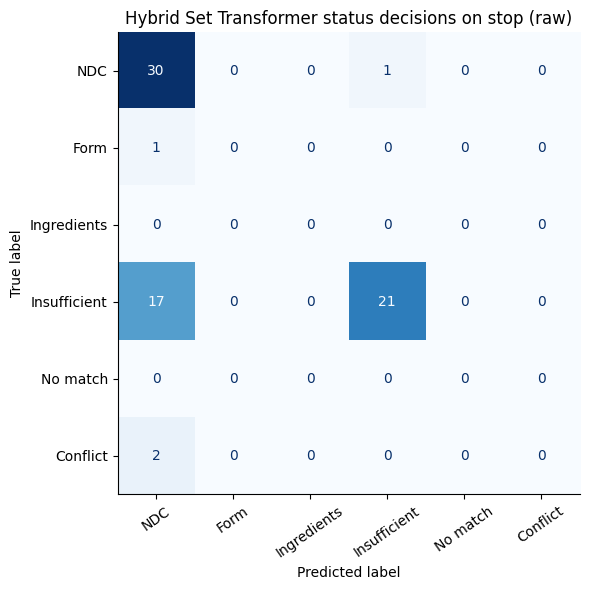

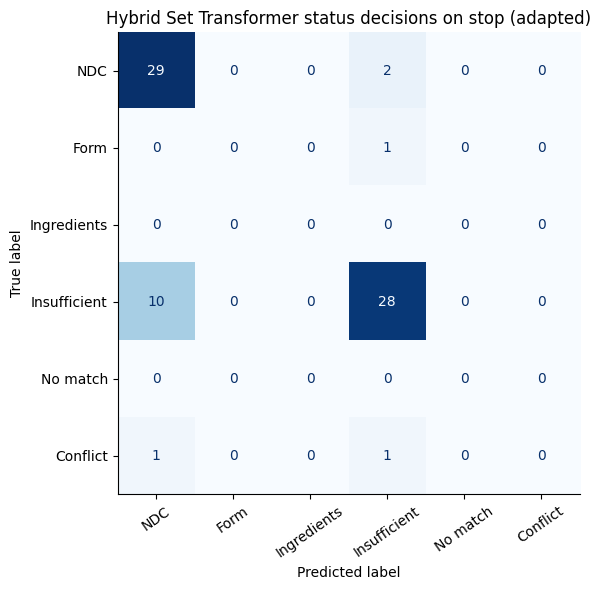

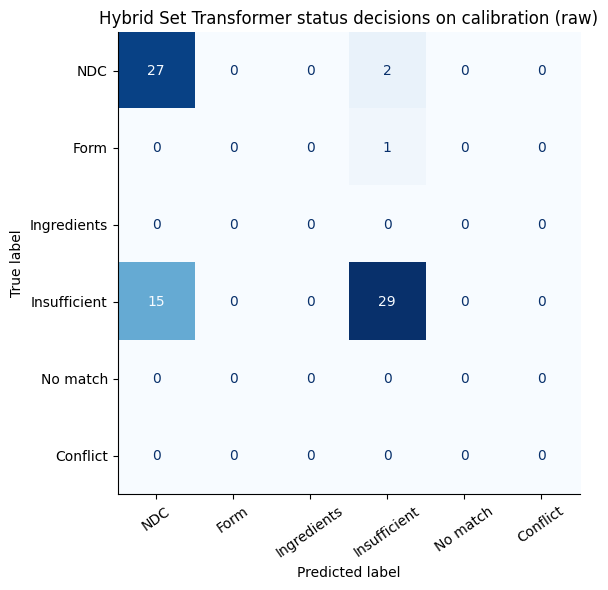

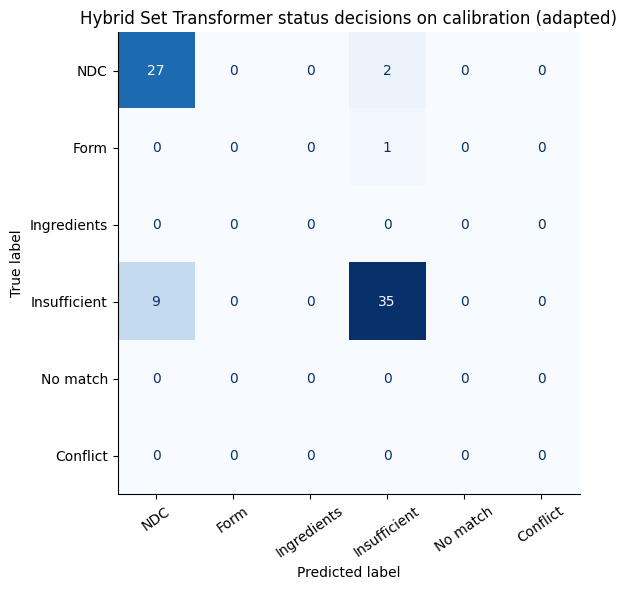

Development artifacts /content/drive/MyDrive/1_MSAI/8_AIH/HRP/data/hybrid_set_transformer_outputs/set_transformer_20261121T141318Z_5ee854b9/evaluations/development_704310e8


In [36]:
validation_reports = {}
development_decisions = {}
prediction_times = {}
inference_start = time.perf_counter()
for part in ("stop", "calibration"):
    prediction_start = time.perf_counter()
    decisions = calibration_decisions if part == "calibration" else predict_dataset(datasets[part])
    development_decisions[part] = decisions
    prediction_times[part] = calibration_seconds if part == "calibration" else time.perf_counter() - prediction_start
    report, predictions, diagnostics = evaluate(used[part], decisions, resolver, thresholds)
    validation_reports[part] = report
    for row in used[part]:
        output = predictions[row["case_id"]]
        jsonschema.validate(output, output_schema)
        contract.parse_output(output, row["payload"])
    dump_json(EVALUATION_ROOT / (part + "_metrics.json"), report)
    # Unique names preserve earlier analysis when a training run is resumed
    suffix = uuid.uuid4().hex[:8]
    write_jsonl(EVALUATION_ROOT / (part + "_predictions_" + suffix + ".jsonl.gz"),
                ({"case_id": key, "output": value} for key, value in predictions.items()))
    write_jsonl(EVALUATION_ROOT / (part + "_adapter_changes_" + suffix + ".jsonl.gz"), diagnostics)
    save_development_artifacts(EVALUATION_ROOT, part, used[part], decisions, predictions,
                               report, thresholds, prediction_times[part])
    regenerate_status_figures(EVALUATION_ROOT, part, "Hybrid Set Transformer status decisions on " + part)
development_seconds = time.perf_counter() - inference_start

print("Development artifacts", EVALUATION_ROOT)


## 7.4 Inspect early-stopping validation metrics

These scores use the reserved early-stopping families and the frozen output contract.


In [37]:
stop_metrics_df = pd.DataFrame([{"metric": key, **value}
    for key, value in validation_reports["stop"]["overall"].items()
    if isinstance(value, dict) and "denominator" in value])
stop_metrics_df


,metric,numerator,denominator,value
0,valid_output_rate,64,64,1.000000
1,joint_case_accuracy,50,64,0.781250
2,ingredient_set_accuracy,29,32,0.906250
3,comparison_accuracy,2,2,1.000000
4,abstention_accuracy,28,40,0.700000
5,unique_ndc_accuracy,29,31,0.935484
6,full_formulation_accuracy,2,4,0.500000
7,ingredient_precision,43,54,0.796296
8,ingredient_recall,43,46,0.934783
9,ingredient_f1,86,100,0.860000


## 7.5 Inspect calibration metrics

These scores describe the families used to fit thresholds and remain separate from early-stopping validation.


In [38]:
calibration_metrics_df = pd.DataFrame([{"metric": key, **value}
    for key, value in validation_reports["calibration"]["overall"].items()
    if isinstance(value, dict) and "denominator" in value])
calibration_metrics_df


,metric,numerator,denominator,value
0,valid_output_rate,64,64,1.000000
1,joint_case_accuracy,49,64,0.765625
2,ingredient_set_accuracy,27,30,0.900000
3,comparison_accuracy,0,0,NaN
4,abstention_accuracy,35,44,0.795455
5,unique_ndc_accuracy,27,29,0.931034
6,full_formulation_accuracy,1,8,0.125000
7,ingredient_precision,34,46,0.739130
8,ingredient_recall,34,40,0.850000
9,ingredient_f1,68,86,0.790698


## 7.6 Inspect raw heads and adapter changes

Compare learned head metrics, raw pipeline joint accuracy and deterministic adapter interventions for each development split.


In [39]:
development_diagnostics = {part: {
    "raw_head_metrics": report["raw"],
    "raw_pipeline_joint_accuracy": report["raw_pipeline"]["overall"]["joint_case_accuracy"],
    "adapter_interventions": {key: report[key] for key in
        ("adapter_status_changes", "adapter_form_changes", "adapter_intervened_requests", "adapter_reason_counts")}
} for part, report in validation_reports.items()}
development_diagnostics


{'stop': {'raw_head_metrics': {'status_accuracy': {'numerator': 51,
    'denominator': 72,
    'value': 0.7083333333333334},
   'status_confusion': [[30, 0, 0, 1, 0, 0],
    [1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [17, 0, 0, 21, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [2, 0, 0, 0, 0, 0]],
   'top_record_source_support': {'numerator': 32,
    'denominator': 32,
    'value': 1.0},
   'mixed_source_support_requests': 0,
   'source_support': {'precision': {'numerator': 31,
     'denominator': 53,
     'value': 0.5849056603773585},
    'recall': {'numerator': 31,
     'denominator': 33,
     'value': 0.9393939393939394},
    'f1': {'numerator': 62, 'denominator': 86, 'value': 0.7209302325581395}},
   'source_support_target': 'source assessment support rather than query intent',
   'sufficiency': {'precision': {'numerator': 32,
     'denominator': 53,
     'value': 0.6037735849056604},
    'recall': {'numerator': 32, 'denominator': 32, 'value': 1.0},
    'f1': {'numerator': 64, 'denominat

## 7.7 Plot learning curves

Save development loss and status curves for this run. The report uses the separately verified six epoch training history. Prediction time is measured separately from plotting and metric computation.

`history.csv` uses `stop_` for early-stopping validation and includes all four head losses, total losses, both accuracies, the learning rate used, epoch seconds and best validation loss, optimizer/overflow counts and scale endpoints. Older history rows leave numerical counts unavailable rather than inventing zeros. Earlier checkpoints reconstruct omitted learning rates from the original cosine schedule and mark those rows. `regenerate_training_figures(run_directory)` reads only this CSV.


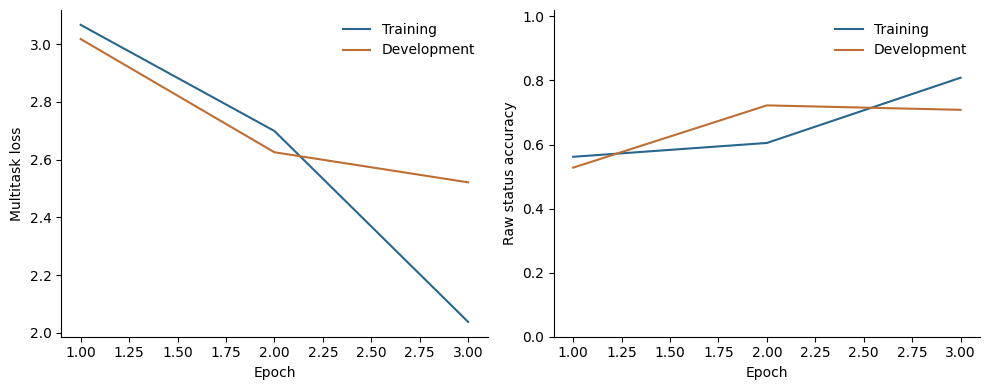

In [40]:
def regenerate_training_figures(root):
    # Run this function independently with saved history.csv, pandas and Matplotlib.
    root = Path(root)
    frame = pd.read_csv(root / "history.csv")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for prefix, label, color in (("train", "Training", "#28668c"), ("stop", "Development", "#be6e34")):
        axes[0].plot(frame["epoch"], frame[prefix + "_total_loss"], label=label, color=color)
        axes[1].plot(frame["epoch"], frame[prefix + "_status_accuracy"], label=label, color=color)
    axes[0].set(xlabel="Epoch", ylabel="Multitask loss")
    axes[1].set(xlabel="Epoch", ylabel="Raw status accuracy", ylim=(0, 1.02))
    for ax in axes:
        ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(root / "training_curves.png", dpi=300, bbox_inches="tight")
    plt.show()
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for ax, head in zip(axes.flat, ("candidate", "status", "sufficiency", "form")):
        for prefix, label in (("train", "Training"), ("stop", "Development")):
            ax.plot(frame["epoch"], frame[prefix + "_" + head + "_loss"], label=label)
        ax.set(xlabel="Epoch", ylabel="Loss", title=head)
        ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(root / "individual_losses.png", dpi=300, bbox_inches="tight")
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(frame["epoch"], frame["learning_rate"])
    ax.set(xlabel="Epoch", ylabel="Learning rate used")
    fig.tight_layout()
    fig.savefig(root / "learning_rate.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

regenerate_training_figures(RUN_ROOT)


## 7.8 Inspect development prediction speed

Report prediction throughput separately from metric calculation and plotting.


In [41]:
speed_summary = {
    "development_evaluation_seconds": development_seconds,
    "warm_requests_per_second": sum(len(datasets[p]) for p in prediction_times) / sum(prediction_times.values())
}
speed_summary


{'development_evaluation_seconds': 4.511972474999993,
 'warm_requests_per_second': 712.7852873071444}

## 7.9 Inspect source-support scores

Review one development request to see which records the head considers supported. The scores do not determine which medicine a user intended.


In [42]:
# Inspect learned support scores on one development request
example_index = next((i for i, item in enumerate(datasets["stop"].items)
                      if len(item["candidates"]) > 1), 0)
example = datasets["stop"].items[example_index]
example_decision = development_decisions["stop"][example_index]
print("Development query", example["request"])
source_support_df = pd.DataFrame([
    {"name": candidate["display_name"], "product_ndc": candidate["product_ndc"], "learned_support": score}
    for candidate, score in zip(example["candidates"], example_decision["candidate"])
])
source_support_df


Development query {'name': 'natouch'}


,name,product_ndc,learned_support
0,natouch,79073-003,0.712532
1,natouch,79073-006,0.726717
2,natouch,79073-008,0.719186
3,natouch,79073-017,0.752740
4,natouch,79073-019,0.651244
5,natouch,79073-028,0.758153


# 8. Export and reload the inference package

The package contains weights, configuration, thresholds, the regular `model_source.py` module and the verified shared dependencies. Source is copied directly without recovering code from notebook cells.

If the current session stopped at the old Section 8.3 error, upload `model_source.py`, rerun the import cell in Section 1.2 and Section 3.1, then run Sections 8.1 through 8.5. Keep the existing Section 7 results and thresholds. Do not rerun Section 6.5.

In a fresh session, set `RESUME_RUN` to the trained run with its original settings. Run Sections 1 through 6.3, skip Sections 6.4 through 6.6, run Section 8.1 to select `best.pt`, then Section 7 and Sections 8.2 through 8.5. Section 7 repeats development inference and calibration only. No retraining or challenge inference is required.


## 8.1 Restore the trained export checkpoint

Reload `best.pt` with the unchanged state dictionary layout and saved configuration identity. This selects the saved training model without running an optimizer step. The standalone inference loader is defined in `model_source.py`.


In [ ]:
best_state = torch.load(RUN_ROOT / "best.pt", map_location="cpu", weights_only=False)
if best_state["config_sha256"] != sha_value(run_config):
    raise ValueError("Export checkpoint configuration identity differs")
model = model_lib.HybridSetTransformer(**MODEL_CONFIG).to(DEVICE)
model.load_state_dict(best_state["model"], strict=True)
model.eval()
print("Export checkpoint", {"path": str(RUN_ROOT / "best.pt"), "epoch": best_state["epoch"] + 1})


## 8.2 Verify the module to export

Confirm that the Drive source still matches the imported implementation. The exporter copies this file directly and retains its existing inference interface.


In [ ]:
if file_hash(MODEL_SOURCE_PATH) != model_lib.SOURCE_SHA256:
    raise RuntimeError("model_source.py changed after import; reload the verified implementation before export")


## 8.3 Save weights and dependencies

Build the complete package in a temporary directory under the run folder, then rename it to its final inference directory. A failed cell cleans up its temporary files and leaves earlier successful exports intact, so the cell can be rerun safely.


In [ ]:
export_root = RUN_ROOT / ("inference_model_" + uuid.uuid4().hex[:8])
with tempfile.TemporaryDirectory(prefix=".inference_export_", dir=RUN_ROOT) as work:
    package_root = Path(work) / "package"
    package_root.mkdir()
    shutil.copyfile(MODEL_SOURCE_PATH, package_root / "model_source.py")
    if file_hash(package_root / "model_source.py") != model_lib.SOURCE_SHA256:
        raise RuntimeError("The copied model implementation differs from the imported module")
    torch.save(model.state_dict(), package_root / "model.pt")
    dump_json(package_root / "model_config.json", MODEL_CONFIG)
    dump_json(package_root / "thresholds.json", thresholds)
    dump_json(package_root / "inference_config.json", {
        "batch_size": TRAIN_CONFIG["batch_size"], "set_slot_budget": SET_SLOT_BUDGET, "seed": SEED,
        "precision": "fp16" if USE_AMP else "fp32"
    })
    (package_root / "requirements.txt").write_text(
        "\n".join(name + "==" + metadata.version(name) for name in requirements) + "\n", encoding="utf-8"
    )
    shutil.copyfile(DATA_ROOT / "otc_shared.py", package_root / "otc_shared.py")
    shutil.copytree(DATA_ROOT / "frozen", package_root / "frozen")
    for name in ("encoding.json", "ingredient_identities.jsonl.gz", "output_schema.json"):
        shutil.copyfile(DATA_ROOT / name, package_root / name)
    dependency_names = ["otc_shared.py", "encoding.json", "ingredient_identities.jsonl.gz", "output_schema.json"]
    dependency_names.extend(name for name in manifest["files"] if name.startswith("frozen/"))
    for name in dependency_names:
        if file_hash(package_root / name) != manifest["files"][name]:
            raise ValueError("Exported dependency differs from the verified bundle: " + name)
    package_root.rename(export_root)
INFERENCE_ROOT = export_root
print("Saved inference package", INFERENCE_ROOT)


## 8.4 Import and test the saved module

Import the copied module and load its weights with strict state matching. Compare every saved tensor, all four output heads and request probabilities against `best.pt`, using only a training fixture. A mismatch stops export verification.


In [ ]:
module_name = "saved_otc_model_" + uuid.uuid4().hex[:8]
module_spec = importlib.util.spec_from_file_location(module_name, INFERENCE_ROOT / "model_source.py")
saved_module = importlib.util.module_from_spec(module_spec)
sys.modules[module_name] = saved_module
try:
    module_spec.loader.exec_module(saved_module)
    reloaded = saved_module.load_inference_model(INFERENCE_ROOT, device=DEVICE)
    if reloaded.state_dict().keys() != best_state["model"].keys():
        raise RuntimeError("Saved inference parameter names differ from best.pt")
    for name, value in reloaded.state_dict().items():
        if not torch.equal(value.cpu(), best_state["model"][name].cpu()):
            raise RuntimeError("Saved inference tensor differs from best.pt: " + name)
    fixture = [datasets["train"][0]]
    features = move(collate(fixture)[0])
    saved_features = saved_module.move(saved_module.collate(fixture)[0])
    with torch.no_grad():
        original_output, saved_output = model(features), reloaded(saved_features)
    for name in original_output:
        if not torch.allclose(original_output[name], saved_output[name], atol=1e-6, rtol=1e-5):
            raise RuntimeError("Saved inference checkpoint differs for " + name)
    fixture_rows = [used["train"][0]]
    original_decisions = predict_dataset(MedicineSets(fixture_rows))
    saved_decisions = saved_module.predict_dataset(saved_module.MedicineSets(fixture_rows))
    if len(original_decisions) != len(saved_decisions):
        raise RuntimeError("Saved inference request count differs")
    for original, saved in zip(original_decisions, saved_decisions):
        for name in original:
            if not np.allclose(original[name], saved[name], atol=1e-6, rtol=1e-5):
                raise RuntimeError("Saved inference probabilities differ for " + name)
    print("Verified best.pt tensors, all output heads and training-fixture probabilities")
finally:
    sys.modules.pop(module_name, None)
del reloaded, saved_module


## 8.5 Freeze the inference artifacts

Record hashes, observed classes, timing and model size. Smoke checkpoints remain ineligible for final inference.


In [ ]:
model_files = sorted(path for path in INFERENCE_ROOT.rglob("*") if path.is_file()
                     and "__pycache__" not in path.parts)
frozen = {
    "complete_training": not SMOKE_TEST and RUN_FULL_TRAINING,
    "model_config": MODEL_CONFIG, "training_config": TRAIN_CONFIG, "thresholds": thresholds,
    "head_semantics": {"candidate": "source support rather than query intent"},
    "unsupported_statuses": [name for index, name in enumerate(STATUS) if status_counts[index] == 0],
    "binary_target_counts": binary_counts,
    "bundle_manifest_sha256": bundle_hash,
    "split_data_sha256": schema_info["split_data_sha256"],
    "identity_mapping_sha256": schema_info["identity_mapping_sha256"],
    "output_schema_sha256": schema_info["output_schema_sha256"],
    "shared_code_sha256": file_hash(DATA_ROOT / "otc_shared.py"),
    "files": {path.relative_to(INFERENCE_ROOT).as_posix(): file_hash(path) for path in model_files},
    "checkpoint_identifier": file_hash(INFERENCE_ROOT / "model.pt"),
    "model_source_sha256": model_lib.SOURCE_SHA256,
    "best_epoch": best_state["epoch"] + 1,
    "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
    "model_bytes": (INFERENCE_ROOT / "model.pt").stat().st_size,
    "training_seconds": elapsed_training,
    "development_evaluation_seconds": development_seconds,
    "development_prediction_seconds": sum(prediction_times.values()),
    "development_requests_per_second": sum(len(datasets[part]) for part in prediction_times) / sum(prediction_times.values()),
    "scoring_contract": SCORING_CONTRACT_VERSION,
    "packages": {name: metadata.version(name) for name in requirements},
    "device": str(DEVICE), "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
    "challenge_used_for_training_or_calibration": False
}
dump_json(INFERENCE_ROOT / "frozen.json", frozen)
inference_summary = {
    "inference_model": str(INFERENCE_ROOT), "parameters": frozen["parameter_count"],
    "model_size_mb": round(frozen["model_bytes"] / 2**20, 2)
}
inference_summary


# 9. Final source-only inference

Keep RUN_FINAL_CHALLENGE_INFERENCE disabled until complete training and every configuration choice are frozen. This stage reads source payloads only and cannot compute challenge accuracy.


## 9.1 Save fixed predictions for local scoring

Export complete JSON outputs, raw decisions and adapter logs. The frozen predictions are evaluated in Notebook 08 using the common scoring contract.


In [ ]:
if RUN_FINAL_CHALLENGE_INFERENCE:
    if not MODEL_SETTINGS_FROZEN or not frozen["complete_training"]:
        raise RuntimeError("Final inference requires a frozen complete training run")
    for name, expected in frozen["files"].items():
        if file_hash(INFERENCE_ROOT / name) != expected:
            raise ValueError("A frozen model file changed " + name)
    if (file_hash(MODEL_SOURCE_PATH) != frozen["model_source_sha256"]
            or model_lib.SOURCE_SHA256 != frozen["model_source_sha256"]):
        raise RuntimeError("Model implementation changed after export")
    if file_hash(DATA_ROOT / "manifest.json") != frozen["bundle_manifest_sha256"]:
        raise ValueError("The prepared bundle changed")
    challenge_rows = list(read_jsonl(DATA_ROOT / "challenge_inputs.jsonl.gz"))
    if len(challenge_rows) != 230 or {r["case_id"] for r in challenge_rows} != set(split_info["challenge_case_ids"]):
        raise ValueError("Unexpected final source inventory")
    if sha_value(challenge_rows) != schema_info["challenge_payload_sha256"]:
        raise ValueError("Final source payloads changed")
    for row in challenge_rows:
        if set(row) != {"case_id", "payload"}:
            raise ValueError("Only source inputs are permitted for final inference")
        check_payload(row["payload"])
    # Reload frozen weights and thresholds before producing any final decisions
    fixed_config = json.loads((INFERENCE_ROOT / "model_config.json").read_text(encoding="utf-8"))
    model = HybridSetTransformer(**fixed_config).to(DEVICE)
    model.load_state_dict(torch.load(INFERENCE_ROOT / "model.pt", map_location=DEVICE, weights_only=True))
    thresholds = json.loads((INFERENCE_ROOT / "thresholds.json").read_text(encoding="utf-8"))
    final_dataset = MedicineSets(challenge_rows, labelled=False)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    decisions = predict_dataset(final_dataset)
    predictions, raw_rows, adapter_rows, cursor = [], [], [], 0
    for row in challenge_rows:
        n = len(row["payload"]["products"])
        local = decisions[cursor:cursor + n]
        output, changes = adapt_case(row["payload"], local, resolver, thresholds)
        contract.parse_output(output, row["payload"])
        jsonschema.validate(output, output_schema)
        predictions.append({"case_id": row["case_id"], "output": output})
        raw_rows.append({"case_id": row["case_id"], "decisions": local})
        adapter_rows.append({"case_id": row["case_id"], "changes": changes})
        cursor += n
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    FINAL_ROOT = RUN_ROOT / ("final_" + uuid.uuid4().hex[:8])
    FINAL_ROOT.mkdir(exist_ok=False)
    PREDICTION_PATH = FINAL_ROOT / "set_transformer_predictions.jsonl.gz"
    write_jsonl(PREDICTION_PATH, predictions)
    write_jsonl(FINAL_ROOT / "raw_decisions.jsonl.gz", raw_rows)
    write_jsonl(FINAL_ROOT / "adapter_changes.jsonl.gz", adapter_rows)
    final_info = {
        **frozen,
        "prediction_sha256": file_hash(PREDICTION_PATH),
        "challenge_payload_sha256": sha_value(challenge_rows),
        "inference_seconds": seconds, "cases_per_second": 230 / seconds,
        "request_count": len(final_dataset),
        "peak_cuda_bytes": torch.cuda.max_memory_allocated() if DEVICE.type == "cuda" else None,
        "raw_decisions_file": "raw_decisions.jsonl.gz",
        "raw_decisions_sha256": file_hash(FINAL_ROOT / "raw_decisions.jsonl.gz"),
        "frozen_model_metadata_sha256": file_hash(INFERENCE_ROOT / "frozen.json")
    }
    dump_json(FINAL_ROOT / "prediction_freeze.json", final_info)
    print("Copy final inference artifacts", {
        "predictions": str(PREDICTION_PATH), "metadata": str(FINAL_ROOT / "prediction_freeze.json"),
        "raw_decisions": str(FINAL_ROOT / "raw_decisions.jsonl.gz"),
        "adapter_log": str(FINAL_ROOT / "adapter_changes.jsonl.gz")
    })
else:
    print("Final inference is disabled")


## 10 Understand absent classes and deterministic rules

The older references contain no NO_MATCH or SOURCE_CONFLICT examples. Exact-source preparation may produce source-conflict labels for the existing queries. A status absent from the actual training subset remains masked and is reported as unsupported.

Empty candidate sets map to NO_MATCH through an explicit structural rule. There is no general deterministic source-conflict detector in model inference. The source-support head measures record support, not intended-medicine selection. Report raw heads and adapter contributions alongside final accuracy.


# 11 Use the exported package independently

Keep the entire inference folder together and use `import model_source`. The copied module contains the same architecture and encoders imported by the notebook. Call `model_source.load_inference_model` with that folder, create `model_source.MedicineSets` from source-only case rows with `labelled=False`, then call `model_source.predict_dataset`. Use the adjacent shared adapter and ingredient identity mapping for complete contract outputs.

The final benchmark was previously inspected, and training labels share a source policy with the deterministic comparator. Complete text is retained, but chunk pooling loses long-range order. Memory safeguards reduce padding and convolution activations without guaranteeing a fixed GPU limit for arbitrary input sizes.


# 12. Implementation references

The implementation follows the [PyTorch attention API](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html), [mixed precision API](https://docs.pytorch.org/docs/2.14/amp.html) and [AMP gradient handling examples](https://docs.pytorch.org/docs/2.14/notes/amp_examples.html#gradient-clipping) and [activation checkpointing API](https://docs.pytorch.org/docs/stable/checkpoint.html). The exported frozen scorer remains the evaluation authority.
